# HCC external validation — pan-cancer Hist2Pheno

Seven HE JPEGs (`P1_N`, `P1_T`, `P2_N`, `P3_T`, `P5_N`, `P5_T`, `P7_T`), StarDist nuclei, **no cell-type ground truth** and no 10x JSON.
Predictions are the pan-cancer **cross-section** checkpoint
`D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

The JPEGs have **no OME PhysicalSize**. 96 dpi is a Windows Photo Viewer placeholder.
The finished run used **`MPP_UM = 0.5`** (`HCC.log`). At that value a native 16 px crop is already **8 µm**, so `scale_image` is false.
This notebook uses 0.5 unless the kernel was started with a different `MPP_UM`.

```bash
cd /home/lingyu/ssd2/Python/Hist2Pheno
export MPP_UM=0.5   # replace with the real scanner µm/px
bash code/External_val/HCC/demo.sh dry-run
bash code/External_val/HCC/demo.sh all
```

Outputs: `data/Visium/HCC/pred_pancancer_section/`.


In [1]:
import os
import sys
from pathlib import Path

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code"))

from Hist2Pheno_pkg.external_validation import ExternalCohort

# Finished demo.sh run (code/External_val/HCC/HCC.log). Override only if you
# re-extract features with a different scanner calibration.
MPP_UM = float(os.environ.get("MPP_UM", "0.5"))

_cohort = ExternalCohort(
    name="HCC",
    data_root=REPO / "data" / "Visium" / "HCC",
    repo=REPO,
    he_suffix=".jpg",
    mpp_um=MPP_UM,
)
PRED_ROOT = _cohort.pred_root
composition_table = _cohort.composition_table
discover_samples = _cohort.discover_samples
geometry = _cohort.geometry
sample_paths = _cohort.sample_paths
ensure_l2_probs = _cohort.ensure_l2_probs
plot_spatial = _cohort.plot_spatial
plot_composition = _cohort.plot_composition
# Re-run the plot cell after changing these. Files are written only when SAVE_FIGURES is True.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 160
HE_MAX_SIDE = 1400
MARKER_PX = 2.2

samples = discover_samples()
for sample in samples:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}"
    )
    p = sample_paths(sample)
    print(f"  pred exists: {p['pred'].is_file()}  {p['pred']}")


P1_N  mpp=0.5000 µm/px  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/P1_N/P1_N_stardist_pred.h5ad
P1_T  mpp=0.5000 µm/px  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/P1_T/P1_T_stardist_pred.h5ad
P2_N  mpp=0.5000 µm/px  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/P2_N/P2_N_stardist_pred.h5ad
P3_T  mpp=0.5000 µm/px  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/P3_T/P3_T_stardist_pred.h5ad
P5_N  mpp=0.5000 µm/px  native16=8.00 µm  after rescale=8.0 µm  scale=1.0000
  pred exists: True  /home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/P5_N/P5_N_stardist_

In [2]:
import pandas as pd
from IPython.display import Image, display

missing = [s for s in samples if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        "No predictions yet for "
        + ", ".join(missing)
        + ". Run: MPP_UM=... bash code/External_val/HCC/demo.sh all"
    )

comp = composition_table(samples)

for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {head} =====")
    display(wide.round(3))



===== L1 =====


fraction                                           mean_conf  \
sample          P1_N   P1_T   P2_N   P3_T   P5_N   P5_T   P7_T      P1_N   
class                                                                      
Endothelial    0.748  0.441  0.598  0.402  0.407  0.650  0.390     0.475   
Immune         0.072  0.181  0.273  0.430  0.349  0.088  0.096     0.398   
Epithelial     0.011  0.272  0.056  0.074  0.002  0.000  0.255     0.469   
Stromal        0.169  0.106  0.072  0.094  0.242  0.262  0.258     0.417   
Neural         0.000  0.000    NaN    NaN    NaN    NaN    NaN     0.296   

                           ...                              n           \
sample        P1_T   P2_N  ...   P5_N   P5_T   P7_T      P1_N     P1_T   
class                      ...                                           
Endothelial  0.451  0.471  ...  0.418  0.418  0.439  100321.0  77998.0   
Immune       0.414  0.436  ...  0.406  0.368  0.398    9706.0  31972.0   
Epithelial   0.535  0.483  ...  0.433  0.377  0.573    1426.0  48081.0   
Stromal      0.426  0.403  ...  0.394  0.383  0.434   22701.0  18773.0   
Neural       0.418    NaN  ...    NaN    NaN    NaN       1.0      5.0   

                                                             
sample           P2_N     P3_T     P5_N      P5_T      P7_T  
class                                                        
Endothelial  151096.0  71433.0  72664.0  106663.0  100570.0  
Immune        69057.0  76457.0  62346.0   14485.0   24787.0  
Epithelial    14220.0  13220.0    374.0       7.0   65829.0  
Stromal       18231.0  16676.0  43121.0   42912.0   66634.0  
Neural            NaN      NaN      NaN       NaN       NaN  

[5 rows x 21 columns]


===== L12 =====


fraction                                           mean_conf  \
sample          P1_N   P1_T   P2_N   P3_T   P5_N   P5_T   P7_T      P1_N   
class                                                                      
Myeloid        0.437  0.757  0.801  0.877  0.858  0.452  0.554     0.370   
Stromal        0.489  0.169  0.144  0.097  0.113  0.484  0.365     0.355   
Endothelial    0.061  0.028  0.041  0.013  0.004  0.010  0.016     0.338   
T_cell         0.005  0.004  0.008  0.006  0.025  0.054  0.006     0.313   
Tumor          0.000  0.028  0.001  0.003  0.000    NaN  0.037     0.445   
Epithelial     0.006  0.015  0.005  0.005  0.000  0.000  0.021     0.397   
B_Plasma       0.001  0.000  0.000  0.000    NaN    NaN  0.001     0.258   

                           ...                             n            \
sample        P1_T   P2_N  ...   P5_N   P5_T   P7_T     P1_N      P1_T   
class                      ...                                           
Myeloid      0.476  0.474  ...  0.414  0.331  0.443  58655.0  133791.0   
Stromal      0.377  0.351  ...  0.337  0.310  0.378  65655.0   29932.0   
Endothelial  0.344  0.354  ...  0.337  0.311  0.323   8240.0    4906.0   
T_cell       0.323  0.370  ...  0.333  0.285  0.307    614.0     636.0   
Tumor        0.529  0.507  ...  0.500    NaN  0.535     34.0    4879.0   
Epithelial   0.420  0.437  ...  0.291  0.296  0.450    817.0    2620.0   
B_Plasma     0.270  0.260  ...    NaN    NaN  0.264    140.0      65.0   

                                                              
sample           P2_N      P3_T      P5_N     P5_T      P7_T  
class                                                         
Myeloid      202264.0  155842.0  153138.0  74189.0  142828.0  
Stromal       36369.0   17290.0   20109.0  79439.0   94008.0  
Endothelial   10336.0    2340.0     744.0   1604.0    4070.0  
T_cell         2108.0    1028.0    4426.0   8831.0    1473.0  
Tumor           269.0     465.0      79.0      NaN    9666.0  
Epithelial     1193.0     804.0       9.0      4.0    5467.0  
B_Plasma         65.0      17.0       NaN      NaN     308.0  

[7 rows x 21 columns]


===== L2 =====


fraction                                            \
sample                P1_N   P1_T   P2_N   P3_T   P5_N   P5_T   P7_T   
class                                                                  
Endothelial          0.341  0.249  0.278  0.139  0.205  0.480  0.167   
Plasma               0.433  0.058  0.160  0.172  0.233  0.313  0.131   
Macrophage           0.076  0.395  0.332  0.405  0.240  0.016  0.262   
Fibroblast           0.091  0.125  0.056  0.062  0.230  0.171  0.258   
Neutrophil           0.006  0.009  0.128  0.179  0.054  0.006  0.003   
Tumor                0.001  0.055  0.003  0.007  0.001    NaN  0.072   
DC                   0.000  0.040  0.001  0.001  0.006  0.002  0.019   
Myofibroblast        0.032  0.013  0.013  0.007  0.001  0.001  0.026   
Injury_epithelial    0.012  0.015  0.007  0.004  0.000  0.001  0.031   
CD4_T                0.002  0.003  0.014  0.010  0.029  0.005  0.002   
Epithelial           0.002  0.025  0.004  0.008  0.000    NaN  0.014   
B_cell               0.003  0.009  0.004  0.004  0.000  0.000  0.015   
Tregs                  NaN  0.000  0.000  0.000  0.000  0.005  0.000   
CD8_T                0.000  0.002  0.001  0.000    NaN    NaN  0.000   
NK                   0.001  0.002  0.000  0.000  0.000  0.000  0.000   
Stromal              0.001  0.001  0.001  0.001  0.000    NaN    NaN   
Alveolar             0.001  0.000  0.000  0.000  0.000    NaN  0.000   

                  mean_conf                ...                             n  \
sample                 P1_N   P1_T   P2_N  ...   P5_N   P5_T   P7_T     P1_N   
class                                      ...                                 
Endothelial           0.256  0.244  0.260  ...  0.212  0.204  0.238  45726.0   
Plasma                0.251  0.221  0.235  ...  0.221  0.219  0.241  58124.0   
Macrophage            0.216  0.279  0.269  ...  0.206  0.173  0.275  10260.0   
Fibroblast            0.230  0.261  0.237  ...  0.204  0.193  0.272  12222.0   
Neutrophil            0.227  0.293  0.305  ...  0.249  0.253  0.265    762.0   
Tumor                 0.342  0.419  0.377  ...  0.397    NaN  0.430     84.0   
DC                    0.193  0.284  0.230  ...  0.213  0.181  0.278     24.0   
Myofibroblast         0.227  0.206  0.229  ...  0.203  0.217  0.219   4254.0   
Injury_epithelial     0.266  0.231  0.256  ...  0.217  0.219  0.280   1577.0   
CD4_T                 0.204  0.193  0.222  ...  0.198  0.151  0.198    233.0   
Epithelial            0.329  0.280  0.296  ...  0.152    NaN  0.280    233.0   
B_cell                0.194  0.239  0.210  ...  0.168  0.147  0.248    356.0   
Tregs                   NaN  0.208  0.192  ...  0.182  0.189  0.174      NaN   
CD8_T                 0.173  0.234  0.250  ...    NaN    NaN  0.212      1.0   
NK                    0.191  0.188  0.171  ...  0.190  0.162  0.179    116.0   
Stromal               0.282  0.353  0.316  ...  0.409    NaN    NaN    108.0   
Alveolar              0.223  0.249  0.218  ...  0.219    NaN  0.217     75.0   

                                                                         
sample                P1_T     P2_N     P3_T     P5_N     P5_T     P7_T  
class                                                                    
Endothelial        44048.0  70128.0  24791.0  36611.0  78732.0  43044.0  
Plasma             10190.0  40367.0  30552.0  41629.0  51418.0  33824.0  
Macrophage         69908.0  83959.0  72075.0  42835.0   2657.0  67472.0  
Fibroblast         22158.0  14071.0  11015.0  41001.0  28045.0  66492.0  
Neutrophil          1637.0  32264.0  31789.0   9652.0   1000.0    807.0  
Tumor               9673.0    784.0   1234.0    204.0      NaN  18439.0  
DC                  6987.0    207.0    230.0    989.0    332.0   4805.0  
Myofibroblast       2349.0   3177.0   1173.0    249.0     92.0   6780.0  
Injury_epithelial   2566.0   1755.0    681.0     59.0    112.0   7868.0  
CD4_T                592.0   3573.0   1834.0   5208.0    875.0    616.0  
Epithelial    

[plot] P1_N  nuclei=134,155  neighbor=12.7px  figsize=(17.2, 6.6)  dpi=160  marker_px=2.2
[plot] P1_T  nuclei=176,829  neighbor=16.0px  figsize=(17.2, 6.6)  dpi=160  marker_px=2.2
[plot] P2_N  nuclei=252,604  neighbor=12.8px  figsize=(17.2, 6.6)  dpi=160  marker_px=2.2
[plot] P3_T  nuclei=177,786  neighbor=13.1px  figsize=(17.2, 6.6)  dpi=160  marker_px=2.2
[plot] P5_N  nuclei=178,505  neighbor=19.7px  figsize=(17.2, 6.6)  dpi=160  marker_px=2.2
[plot] P5_T  nuclei=164,067  neighbor=18.2px  figsize=(17.2, 6.6)  dpi=160  marker_px=2.2
[plot] P7_T  nuclei=257,820  neighbor=14.5px  figsize=(17.2, 6.6)  dpi=160  marker_px=2.2


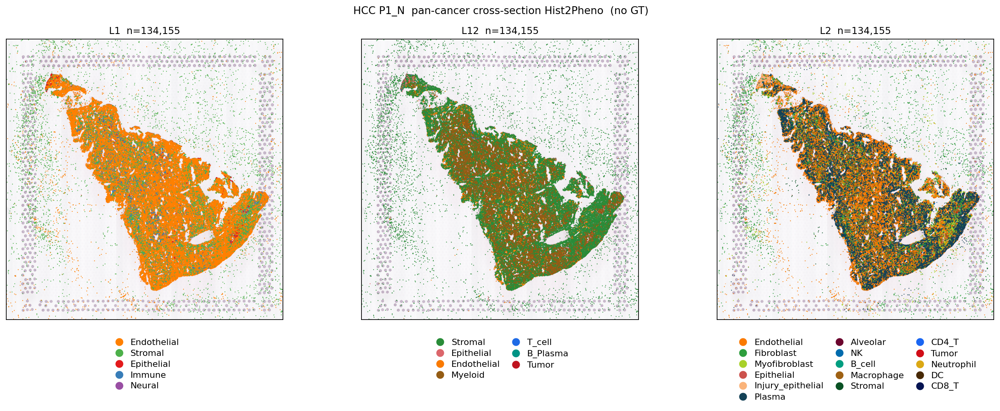

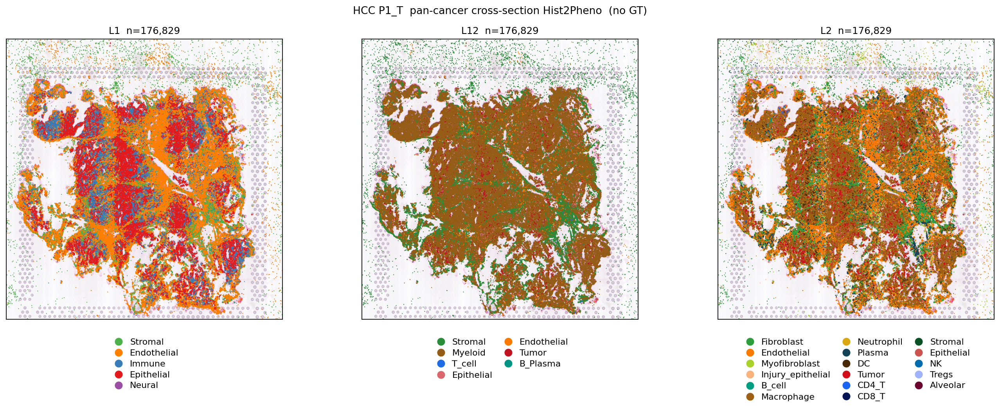

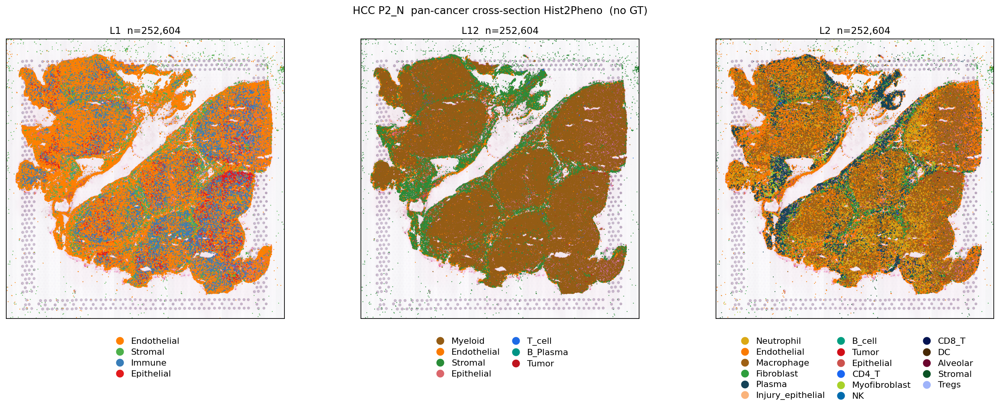

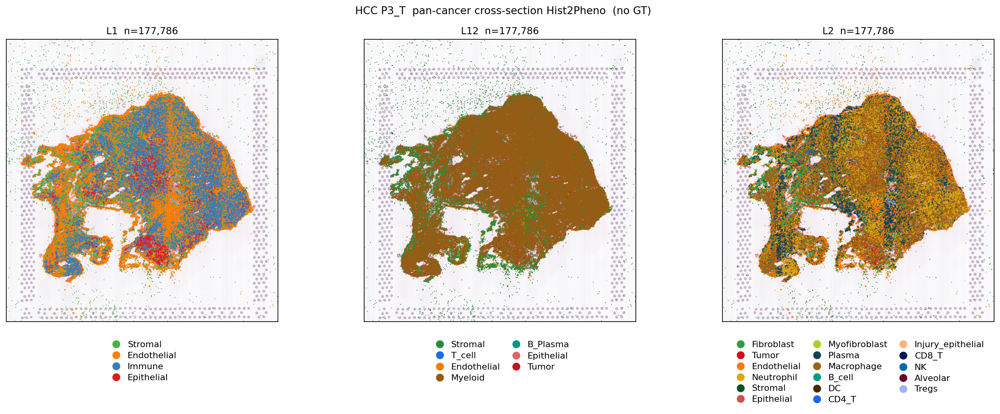

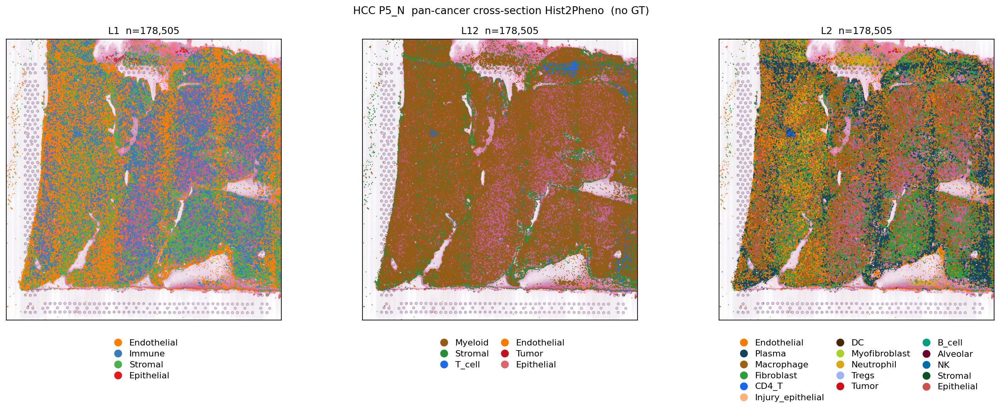

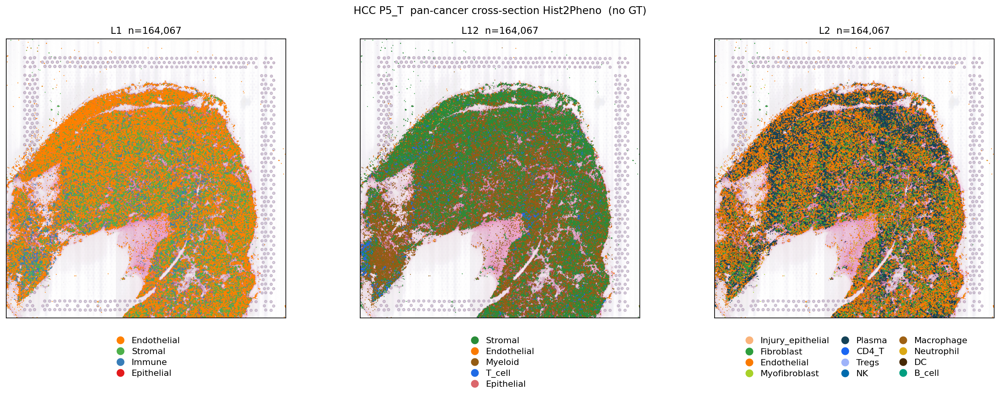

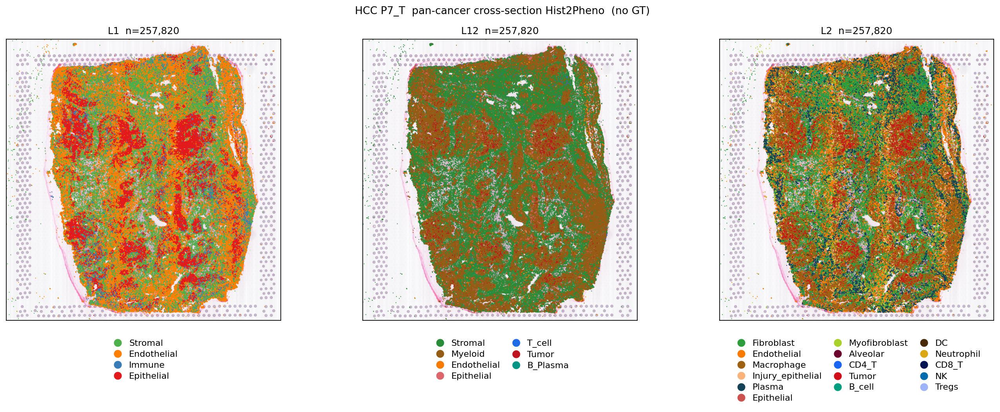

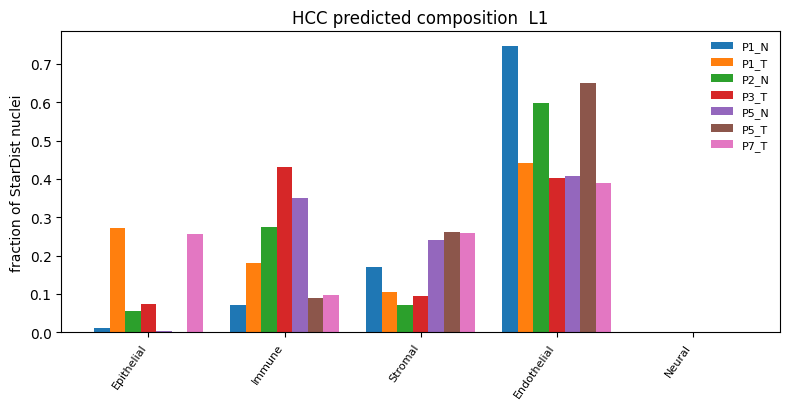

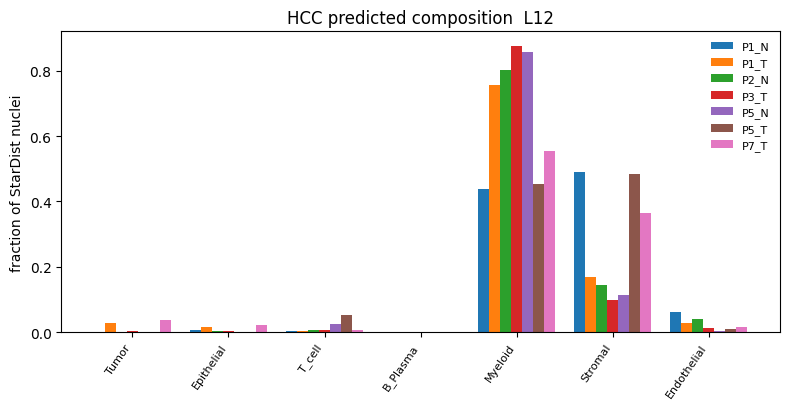

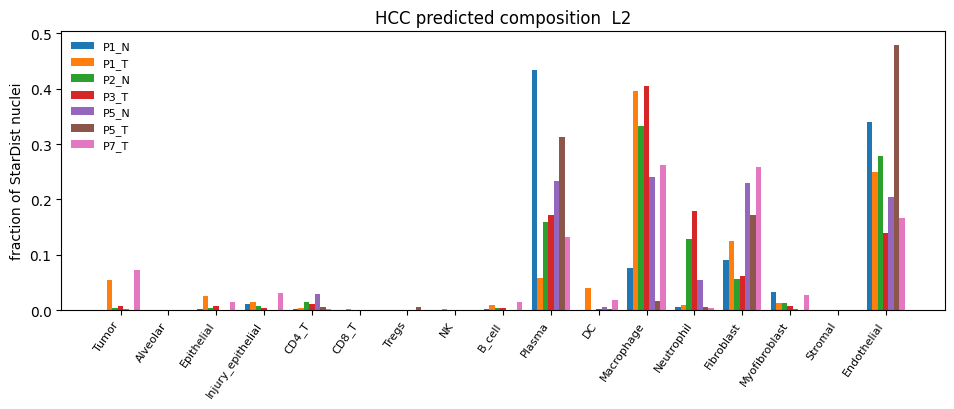

In [3]:
import matplotlib.pyplot as plt

for fig in plot_spatial(
    samples,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
):
    display(fig)
    plt.close(fig)
for fig in plot_composition(samples, save=SAVE_FIGURES):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** is converted with `MPP_UM`, not with 96 dpi and not with 0.5 unless that is the value you set. TLS, SRI, and TNI each use a 1×3 row: abundance, spatial score without markers, then the same spatial map with cyan candidates.


In [4]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

HCC_NICHE = OrganNicheConfig(
    pan_organ="pancancer_hcc",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(samples[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="HCC",
)
display(hni.index_formula_table(HCC_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


In [5]:
import numpy as np
niche_frames = {}
for sample in samples:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        missing = hni.missing_index_cell_types(class_names, HCC_NICHE)
        if missing:
            raise RuntimeError(f"{sample} missing niche compartments: {missing}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, HCC_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, HCC_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    niche_frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )


[niche] cache P1_N_niche_indices.h5ad  n=134,155  µm/px=0.5000
  TLS hotspot: {'n_cells_total': 134155, 'n_candidate_cells': 6708, 'fraction_candidate': 0.05000186351608214, 'max_tls_spatial': 0.13548904477622753, 'mean_tls_spatial_candidate': 0.09975253492878859, 'centroid_x': 7917.479498400174, 'centroid_y': 8498.675246278179}
  mean TLS=0.329  TLS_spatial=0.073  SRI=7.450  TNI=16.624
[niche] cache P1_T_niche_indices.h5ad  n=176,829  µm/px=0.5000
  TLS hotspot: {'n_cells_total': 176829, 'n_candidate_cells': 8842, 'fraction_candidate': 0.050003110349546735, 'max_tls_spatial': 0.16618843371438016, 'mean_tls_spatial_candidate': 0.13265707247459396, 'centroid_x': 8227.98337000955, 'centroid_y': 9010.497982318653}
  mean TLS=0.278  TLS_spatial=0.086  SRI=3.983  TNI=10.616
[niche] cache P2_N_niche_indices.h5ad  n=252,604  µm/px=0.5000
  TLS hotspot: {'n_cells_total': 252604, 'n_candidate_cells': 12631, 'fraction_candidate': 0.050003167012398854, 'max_tls_spatial': 0.17359093616206123, 'mea

[niche] cache P5_N_niche_indices.h5ad  n=178,505  µm/px=0.5000
  TLS hotspot: {'n_cells_total': 178505, 'n_candidate_cells': 8926, 'fraction_candidate': 0.05000420156298143, 'max_tls_spatial': 0.169982322731875, 'mean_tls_spatial_candidate': 0.14117403238047035, 'centroid_x': 11244.876106166475, 'centroid_y': 6984.318162742631}
  mean TLS=0.390  TLS_spatial=0.114  SRI=12.547  TNI=33.025
[niche] cache P5_T_niche_indices.h5ad  n=164,067  µm/px=0.5000
  TLS hotspot: {'n_cells_total': 164067, 'n_candidate_cells': 8204, 'fraction_candidate': 0.050003961796095495, 'max_tls_spatial': 0.1604057299620015, 'mean_tls_spatial_candidate': 0.13482865910598751, 'centroid_x': 5041.7864085266165, 'centroid_y': 11291.309718325218}
  mean TLS=0.402  TLS_spatial=0.115  SRI=6.731  TNI=15.512
[niche] cache P7_T_niche_indices.h5ad  n=257,820  µm/px=0.5000
  TLS hotspot: {'n_cells_total': 257820, 'n_candidate_cells': 12891, 'fraction_candidate': 0.05, 'max_tls_spatial': 0.1675691826105491, 'mean_tls_spatial_c

/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/HCC/pred_pancancer_section/figures/tls_score_summary.csv


,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,P1_N,134155,0.329,0.331,0.475,0.774,0.073,0.074,0.093,0.135,0.427,0.376,0.088,0.162,0.083,0.392
1,P1_T,176829,0.278,0.274,0.471,0.877,0.086,0.084,0.125,0.166,0.675,0.674,0.168,0.288,0.114,0.427
2,P2_N,252604,0.303,0.299,0.467,0.841,0.083,0.083,0.106,0.174,0.458,0.446,0.110,0.198,0.095,0.400
3,P3_T,177786,0.318,0.319,0.459,0.909,0.089,0.089,0.111,0.169,0.558,0.525,0.161,0.277,0.105,0.418
4,P5_N,178505,0.390,0.391,0.506,0.855,0.114,0.115,0.135,0.170,0.610,0.470,0.133,0.235,0.126,0.470
5,P5_T,164067,0.402,0.405,0.484,0.675,0.115,0.117,0.131,0.160,0.475,0.280,0.094,0.172,0.121,0.441
6,P7_T,257820,0.272,0.266,0.469,0.871,0.079,0.077,0.121,0.168,0.643,0.635,0.177,0.301,0.108,0.425


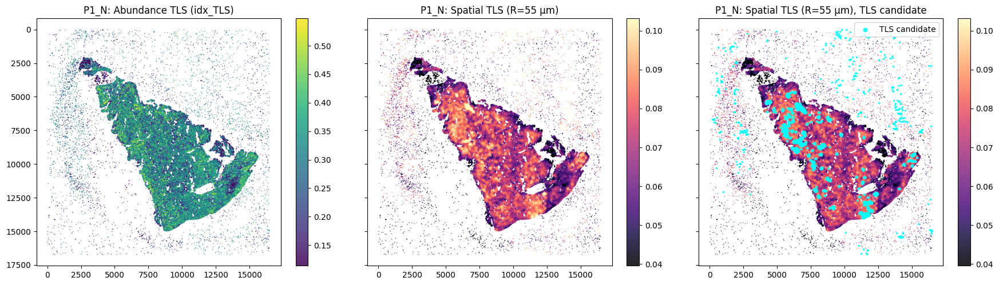

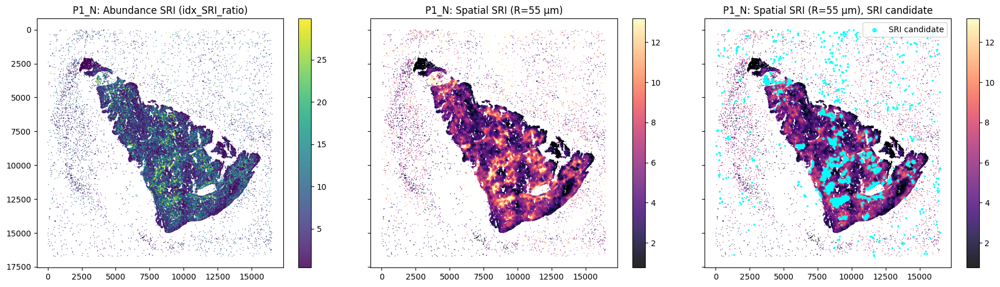

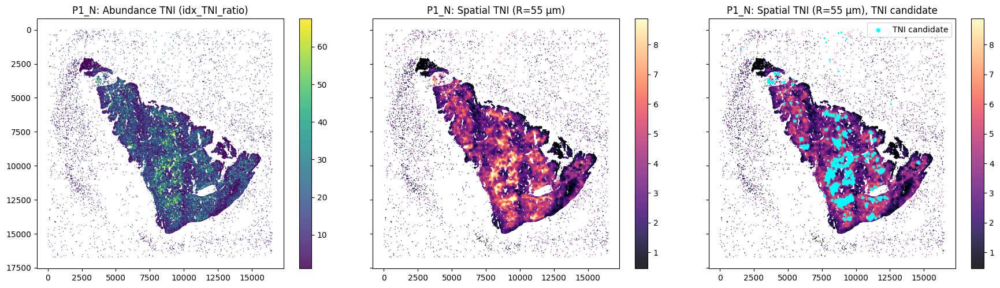

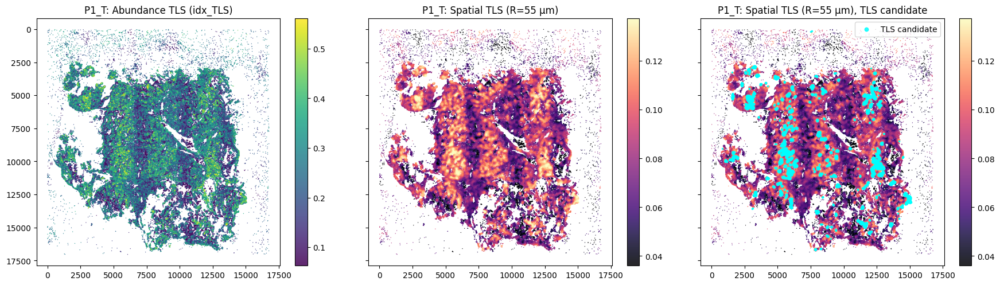

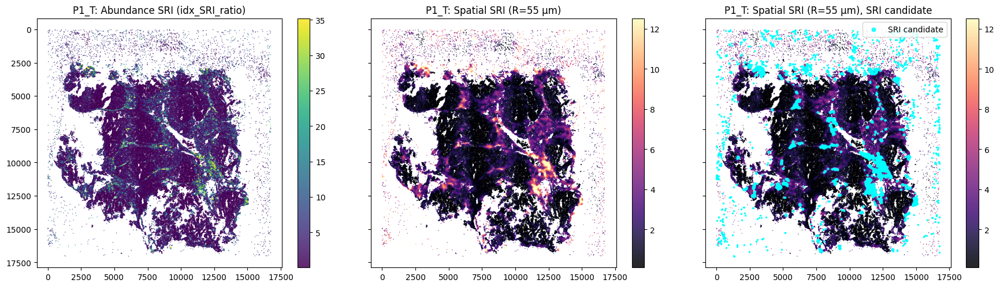

...

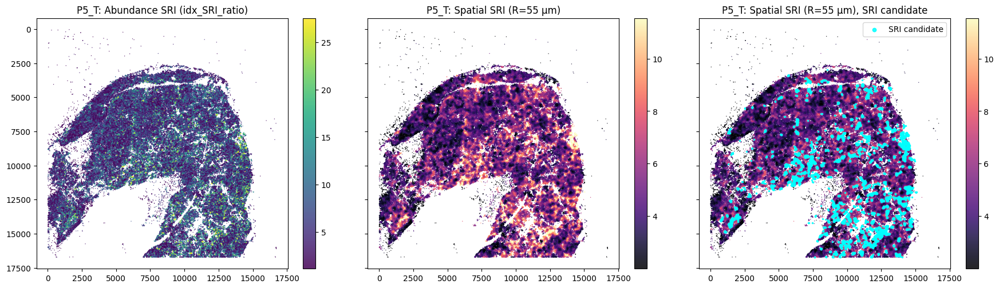

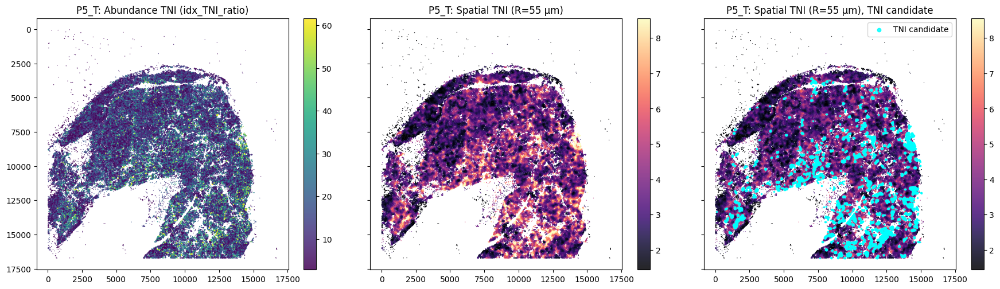

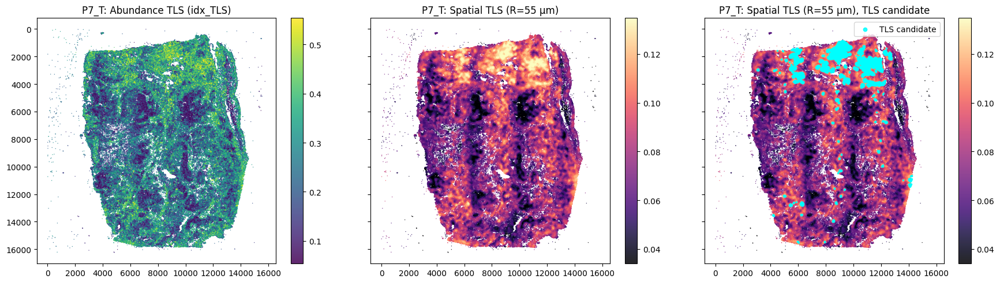

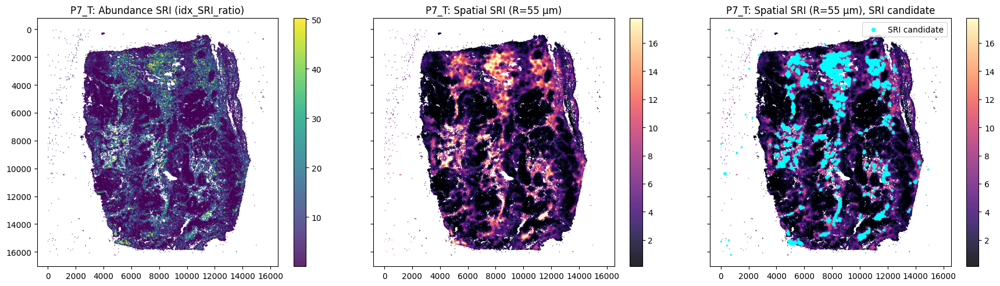

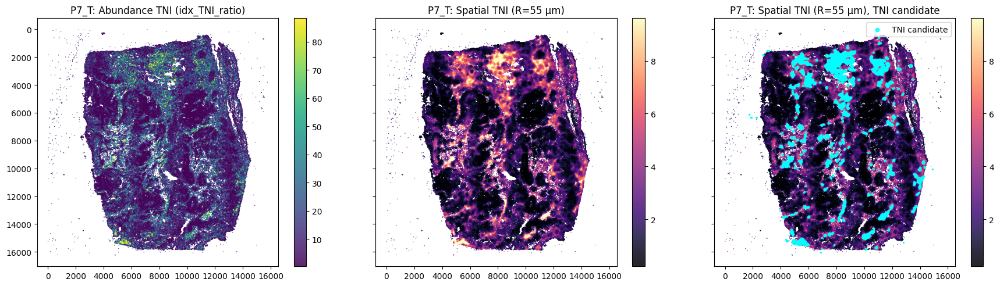

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)


def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }


quant_rows = [tls_score_row(df, sample) for sample, df in niche_frames.items()]
tls_quant = pd.DataFrame(quant_rows)
tls_quant_path = fig_dir / "tls_score_summary.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in niche_frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)

    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
